# Sujet Prédiction de la qualité de soudures

## 1.Setup

### Import libraries

In [2]:
# Python ≥3.5 is required
import sys
assert sys.version_info >= (3, 5)

# Scikit-Learn ≥0.20 is required
import sklearn
assert sklearn.__version__ >= "0.20"

# Numpy arrays are used to store training and test data.
import numpy as np

# Pandas is used to manipulate tabular data.
import pandas as pd

# Matplotlib is used to plot graphs.
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
# Style options for plots.
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

# Import utilities
import os
import tarfile
import urllib
import seaborn as sns

# Ignore useless warnings (see SciPy issue #5998).
import warnings
warnings.filterwarnings(action="ignore", message="^internal gelsd")

# Saves a figure to a file
def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join("./figs", fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

### Import data

In [3]:
URL = "https://www.phase-trans.msm.cam.ac.uk/map/data/tar/welddb.tar"
DATA_DIR = "welddb"
TAR_PATH = "welddb.tar"

os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(TAR_PATH):
    urllib.request.urlretrieve(URL, TAR_PATH)

with tarfile.open(TAR_PATH) as tar:
    tar.extractall(DATA_DIR)

# Check what the archive contains (expected: welddb.data, welddb.info, welddb.tex)
for root, _, files in os.walk(DATA_DIR):
    for f in files:
        print(os.path.join(root, f))

welddb/welddb.data
welddb/welddb.tex
welddb/welddb.info


/var/folders/28/2yq_jml12n7fv09x8xfkzzy40000gn/T/ipykernel_88784/2924528948.py:11: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(DATA_DIR)


### Loading the data with explicit column names and units
The raw file has no header. Column names and units come from the dataset documentation.

The character `N` means "not reported in the publication" (it is **not** zero), so it is read as a missing value (`NaN`).

In [4]:
columns = [
    "C_wt", "Si_wt", "Mn_wt", "S_wt", "P_wt", "Ni_wt", "Cr_wt", "Mo_wt", "V_wt", "Cu_wt",
    "Co_wt", "W_wt", "O_ppm", "Ti_ppm", "N_ppm", "Al_ppm", "B_ppm", "Nb_ppm", "Sn_ppm",
    "As_ppm", "Sb_ppm", "Current_A", "Voltage_V", "AC_DC", "Electrode_polarity",
    "Heat_input_kJmm", "Interpass_C", "Weld_type", "PWHT_temp_C", "PWHT_time_h",
    "Yield_MPa", "UTS_MPa", "Elongation_pct", "Reduction_area_pct",
    "Charpy_temp_C", "Charpy_J", "Hardness_kgmm2", "FATT_50pct",
    "PF_pct", "FS_pct", "AF_pct", "Martensite_pct", "FC_pct", "Weld_ID",
]
materials = pd.read_csv(
    "welddb/welddb.data",
    sep=r"\s+",
    header=None,
    names=columns,
    na_values=["N"],
    engine="python",
)

## 2.Identifying target features

### Overview

In [5]:
pd.set_option('display.max_columns', None)
materials.head()

,C_wt,Si_wt,Mn_wt,S_wt,P_wt,Ni_wt,Cr_wt,Mo_wt,V_wt,Cu_wt,Co_wt,W_wt,O_ppm,Ti_ppm,N_ppm,Al_ppm,B_ppm,Nb_ppm,Sn_ppm,As_ppm,Sb_ppm,Current_A,Voltage_V,AC_DC,Electrode_polarity,Heat_input_kJmm,Interpass_C,Weld_type,PWHT_temp_C,PWHT_time_h,Yield_MPa,UTS_MPa,Elongation_pct,Reduction_area_pct,Charpy_temp_C,Charpy_J,Hardness_kgmm2,FATT_50pct,PF_pct,FS_pct,AF_pct,Martensite_pct,FC_pct,Weld_ID
0,0.037,0.30,0.65,0.008,0.012,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,170.0,21.0,DC,+,1.0,200,MMA,250.0,14.0,392.0,466.0,31.9,80.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aaw
1,0.037,0.30,0.65,0.008,0.012,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,170.0,21.0,DC,+,1.0,200,MMA,0.0,0.0,NaN,NaN,NaN,NaN,-28.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aawch
2,0.037,0.30,0.65,0.008,0.012,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,170.0,21.0,DC,+,1.0,200,MMA,580.0,2.0,370.0,456.0,35.2,80.6,-38.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aht
3,0.037,0.31,1.03,0.007,0.014,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,170.0,21.0,DC,+,1.0,200,MMA,250.0,14.0,413.0,498.0,31.2,80.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Baw
4,0.037,0.31,1.03,0.007,0.014,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,170.0,21.0,DC,+,1.0,200,MMA,0.0,0.0,NaN,NaN,NaN,NaN,-48.0,100.0,NaN,NaN,32,28.0,40.0,0.0,0.0,Evans-Ni/CMn-1990/1991-0Bawch


### Target columns

First we identify input features which can be put in 2 categories. 

**1.Chemical composition:** Columns 1-21

These describe the composition of the weld metal.

**2.Welding parameters** Columns 22–30:

These describe how the weld was produced and treated.

The remaining are outputs measued on the finished weld metal which are mechanical properties. Weld quality is a property of the finished weld, so the
quality variables must be chosen among the outputs, and the inputs are what we use to predict them.

**Candidate quality indicators.** 

The mechanical properties describe three complementary aspects of a weld:

| Aspect | Variables | Meaning |
|---|---|---|
| Toughness | `Charpy_J` (at `Charpy_temp_C`) | Energy absorbed before fracture under impact. A low value means a brittle weld, prone to sudden failure |
| Strength | `Yield_MPa`, `UTS_MPa` | Load the weld can carry without permanent deformation (yield) and before breaking (UTS) |
| Ductility | `Elongation_pct`, `Reduction_area_pct` | Ability to deform plastically before breaking |

We look at the availability of each candidate target and the correlation between them to choose a target that's indicative of the welding quality.

**Choice of target.** 

We select **Yield_MPa** as the main quality variable, for three reasons:


1. *Engineering relevance*: Yield strength is a key mechanical property for evaluating the performance of a welded material. It represents the stress at which the material begins to undergo permanent plastic deformation. Therefore, a higher yield strength generally indicates that the weld metal can withstand higher applied stresses before permanent deformation occurs. 
2. *Data availability*: it has a good rate of availability.
3. *Correlation with 'UTS_MPA'*: Predicting the yield strength is indicative of the ultimate strength.

The other output variables are **never used as inputs**: they are only known after welding and testing, so using them would leak information and make the model useless for its real purpose, which is predicting quality from the welding recipe.
Rows with no Yield_MPA value are **unlabeled data**, exploited later by the semi-supervised approach.

,labeled_rows,labeled_%
Charpy_J,879,53.2
Yield_MPa,780,47.2
UTS_MPa,738,44.7
Elongation_pct,700,42.4
Reduction_area_pct,705,42.7


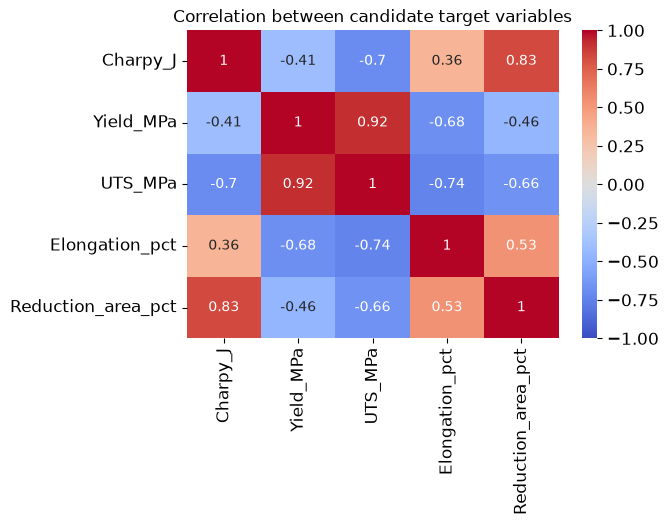

In [6]:
targets = ["Charpy_J", "Yield_MPa", "UTS_MPa", "Elongation_pct", "Reduction_area_pct"]

# Availability of each candidate target
avail = materials[targets].notna().sum().to_frame("labeled_rows")
avail["labeled_%"] = (100 * avail["labeled_rows"] / len(materials)).round(1)
display(avail)

# 2. Correlation between candidate targets (pairwise, on rows where both exist)
plt.figure(figsize=(6, 4))
sns.heatmap(materials[targets].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between candidate target variables")
plt.show()

## 3.Preprocessing

### Descriptive analysis

In [7]:
materials.info()

<class 'pandas.DataFrame'>
RangeIndex: 1652 entries, 0 to 1651
Data columns (total 44 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   C_wt                1652 non-null   float64
 1   Si_wt               1652 non-null   float64
 2   Mn_wt               1652 non-null   float64
 3   S_wt                1648 non-null   str    
 4   P_wt                1642 non-null   float64
 5   Ni_wt               697 non-null    float64
 6   Cr_wt               784 non-null    float64
 7   Mo_wt               793 non-null    str    
 8   V_wt                928 non-null    str    
 9   Cu_wt               578 non-null    str    
 10  Co_wt               129 non-null    str    
 11  W_wt                75 non-null     str    
 12  O_ppm               1256 non-null   float64
 13  Ti_ppm              935 non-null    str    
 14  N_ppm               1242 non-null   str    
 15  Al_ppm              905 non-null    str    
 16  B_ppm            

### Deleting unused output features

These features were identified in section 2. They're candidates variables to represent the quality of the welding but were not chosen, therefore they must deleted to avoid data leakage.

In [8]:
# Delete output features
materials = materials.drop(columns=["Charpy_J", "UTS_MPa", "Elongation_pct", "Reduction_area_pct"])
# We also delete teh "Hardness_kgmm2", "Charpy_temp_C" and "Weld_ID" features
materials = materials.drop(columns=["Hardness_kgmm2", "Charpy_temp_C", "Weld_ID"])


In [9]:
from sklearn.model_selection import train_test_split

# Keep labeled and unlabeled rows together for now.
train, test = train_test_split(
    materials.copy(),
    test_size=0.20,
    random_state=42,
)

print(f"Train: {train.shape}")
print(f"Test: {test.shape}")
print(f"Labeled rows in train: {train['Yield_MPa'].notna().sum()}")
print(f"Unlabeled rows in train: {train['Yield_MPa'].isna().sum()}")

Train: (1321, 37)
Test: (331, 37)
Labeled rows in train: 613
Unlabeled rows in train: 708


### Categorical features
An overview of the data revealed that some numeric features have "str" types, therefore can't be treated as numeric features. We must analyze these columns and try to convert them to numeric if possible.

In [10]:
categorical_expected = ["AC_DC", "Electrode_polarity", "Weld_type"]
numeric_expected = [c for c in train.columns if c not in categorical_expected]

# Columns containing values that need explicit numeric parsing.
suspect = [
    c for c in numeric_expected
    if not pd.api.types.is_numeric_dtype(train[c])
]
print("Columns read as text but expected numeric:", suspect)

for c in suspect:
    bad = train[c].dropna()[
        pd.to_numeric(train[c].dropna(), errors="coerce").isna()
    ]
    print(f"\n{c}: {bad.unique()[:15]}")

Columns read as text but expected numeric: ['S_wt', 'Mo_wt', 'V_wt', 'Cu_wt', 'Co_wt', 'W_wt', 'Ti_ppm', 'N_ppm', 'Al_ppm', 'B_ppm', 'Nb_ppm', 'Sn_ppm', 'As_ppm', 'Sb_ppm', 'Interpass_C', 'PF_pct']

S_wt: <StringArray>
['<0.002']
Length: 1, dtype: str

Mo_wt: <StringArray>
['<0.01']
Length: 1, dtype: str

V_wt: <StringArray>
['<0.0005', '<5', '<0.01', '<0.005']
Length: 4, dtype: str

Cu_wt: <StringArray>
['<0.01']
Length: 1, dtype: str

Co_wt: <StringArray>
['<0.01']
Length: 1, dtype: str

W_wt: <StringArray>
['<0.1']
Length: 1, dtype: str

Ti_ppm: <StringArray>
['<10', '<100', '<0.01', '<5']
Length: 4, dtype: str

N_ppm: <StringArray>
['54tot24res', '66totndres', '67tot33res', '61tot34res', '48tot18res',
 '50tot17res', '52tot18res', '54totndres']
Length: 8, dtype: str

Al_ppm: <StringArray>
['<5', '<100', '<0.01', '<50']
Length: 4, dtype: str

B_ppm: <StringArray>
['<5', '<10']
Length: 2, dtype: str

Nb_ppm: <StringArray>
['<5', '<100', '<6', '<50']
Length: 4, dtype: str

Sn_ppm: <Str

Four patterns are identified , here is how we'll deal with each : 
1. Values under a limit of detection (eg: '<0.01')=> will be replaced with the threshold/2.
(standard convention in analytical chemistry: it avoids both zero and the limit itself, which would bias the mean)
2. Range of values (eg: '150-200')=> will be replaced with midpoint.
3. Values with units (eg: '158(Hv30)') => will be replaced with first value.

### Handling categorical columns that should've been numeric

In [11]:
import re

def parse_value(x, col):
    """Convert one raw entry to a float, following the documented rules."""
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, float, np.number)):
        return float(x)
    s = str(x).strip()

    if s.startswith("<"):
        return float(s[1:]) / 2

    match = re.fullmatch(r"(\d+\.?\d*)-(\d+\.?\d*)", s)
    if match:
        return (float(match.group(1)) + float(match.group(2))) / 2

    match = re.match(r"(\d+\.?\d*)", s)
    if match:
        return float(match.group(1))

    return np.nan

# Parsing is deterministic, so apply the same rule to train and test.
for frame in (train, test):
    for c in suspect:
        frame[c] = frame[c].apply(lambda x: parse_value(x, c))

still_bad = [
    c for c in numeric_expected
    if not pd.api.types.is_numeric_dtype(train[c])
]
print("Colonnes encore non numériques :", still_bad)

Colonnes encore non numériques : []


### Outliers detections

IQR flag many extreme values on composition and process variables. We interpret these as rare but valid weld specifications.

Dropping them would bias the sample toward typical welds and hide the diversity of metals the industrial problem cares about.

Therefore no automatic outlier removal is applied.

Afterwards, we'll prioritise models that handle well outliers.

In [12]:
# Detect possible outliers on the training features only.
num_cols = train.select_dtypes(include="number").columns.tolist()
num_cols = [c for c in num_cols if c != "Yield_MPa"]

def iqr_outlier_mask(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

rows = []
for c in num_cols:
    mask = iqr_outlier_mask(train[c])
    n = int(mask.sum())
    rows.append({
        "column": c,
        "n_outliers": n,
        "pct": round(100 * n / train[c].notna().sum(), 1) if train[c].notna().any() else np.nan,
        "min": train[c].min(),
        "max": train[c].max(),
        "q1": train[c].quantile(0.25),
        "q3": train[c].quantile(0.75),
    })

outlier_summary = pd.DataFrame(rows).sort_values("n_outliers", ascending=False)
display(outlier_summary)

,column,n_outliers,pct,min,max,q1,q3
24,Interpass_C,469,35.5,20.000,300.00,200.00000,200.0000
21,Current_A,247,22.2,115.000,900.00,170.00000,300.0000
8,V_wt,141,18.9,0.000,2.50,0.00025,0.0440
14,N_ppm,139,13.9,21.000,552.00,67.00000,104.0000
1,Si_wt,129,9.8,0.040,1.14,0.27000,0.3600
23,Heat_input_kJmm,128,9.7,0.600,7.90,1.00000,2.0000
12,O_ppm,125,12.4,142.000,1650.00,368.00000,470.0000
5,Ni_wt,98,17.2,0.000,3.50,0.00000,0.2675
3,S_wt,97,7.4,0.001,0.14,0.00600,0.0100
6,Cr_wt,97,15.3,0.000,10.20,0.00000,2.3000


### Missing values estimation
We must estimate how many missing values there are to decide which startegy to use.

In [13]:
materials.isna().sum().sort_values(ascending=False) / len(materials) * 100

FATT_50pct            98.123487
W_wt                  95.460048
FC_pct                94.612591
Martensite_pct        94.612591
AF_pct                94.552058
FS_pct                94.552058
PF_pct                94.067797
Co_wt                 92.191283
As_ppm                85.835351
Sb_ppm                84.261501
Sn_ppm                82.082324
B_ppm                 69.491525
Cu_wt                 65.012107
Ni_wt                 57.808717
Nb_ppm                54.479419
Yield_MPa             52.784504
Cr_wt                 52.542373
Mo_wt                 51.997579
Al_ppm                45.217918
V_wt                  43.825666
Ti_ppm                43.401937
N_ppm                 24.818402
O_ppm                 23.970944
Current_A             15.012107
Voltage_V             15.012107
AC_DC                 13.014528
Electrode_polarity     9.443099
PWHT_temp_C            0.786925
PWHT_time_h            0.786925
P_wt                   0.605327
S_wt                   0.242131
Weld_typ

### Handling columns with missing values

- Dropping colummns with >70% missing values rates .
- Univariate imputation (Median) of the remainder.

In [14]:
# Learn missing-value handling from train only.
min_non_na = int(np.ceil(0.30 * len(train)))
kept_columns = train.columns[train.notna().sum() >= min_non_na]

train = train.loc[:, kept_columns].copy()
test = test.reindex(columns=kept_columns).copy()

# Do not impute the target.
target = "Yield_MPa"
num_cols = [
    c for c in numeric_expected
    if c in train.columns and c != target
]
cat_cols = pd.Index([
    c for c in categorical_expected
    if c in train.columns
])

train_medians = train[num_cols].median()
train[num_cols] = train[num_cols].fillna(train_medians)
test[num_cols] = test[num_cols].fillna(train_medians)

train_modes = {}
for c in cat_cols:
    train_modes[c] = train[c].mode().iloc[0]
    train[c] = train[c].fillna(train_modes[c])
    test[c] = test[c].fillna(train_modes[c])

### Distributions 

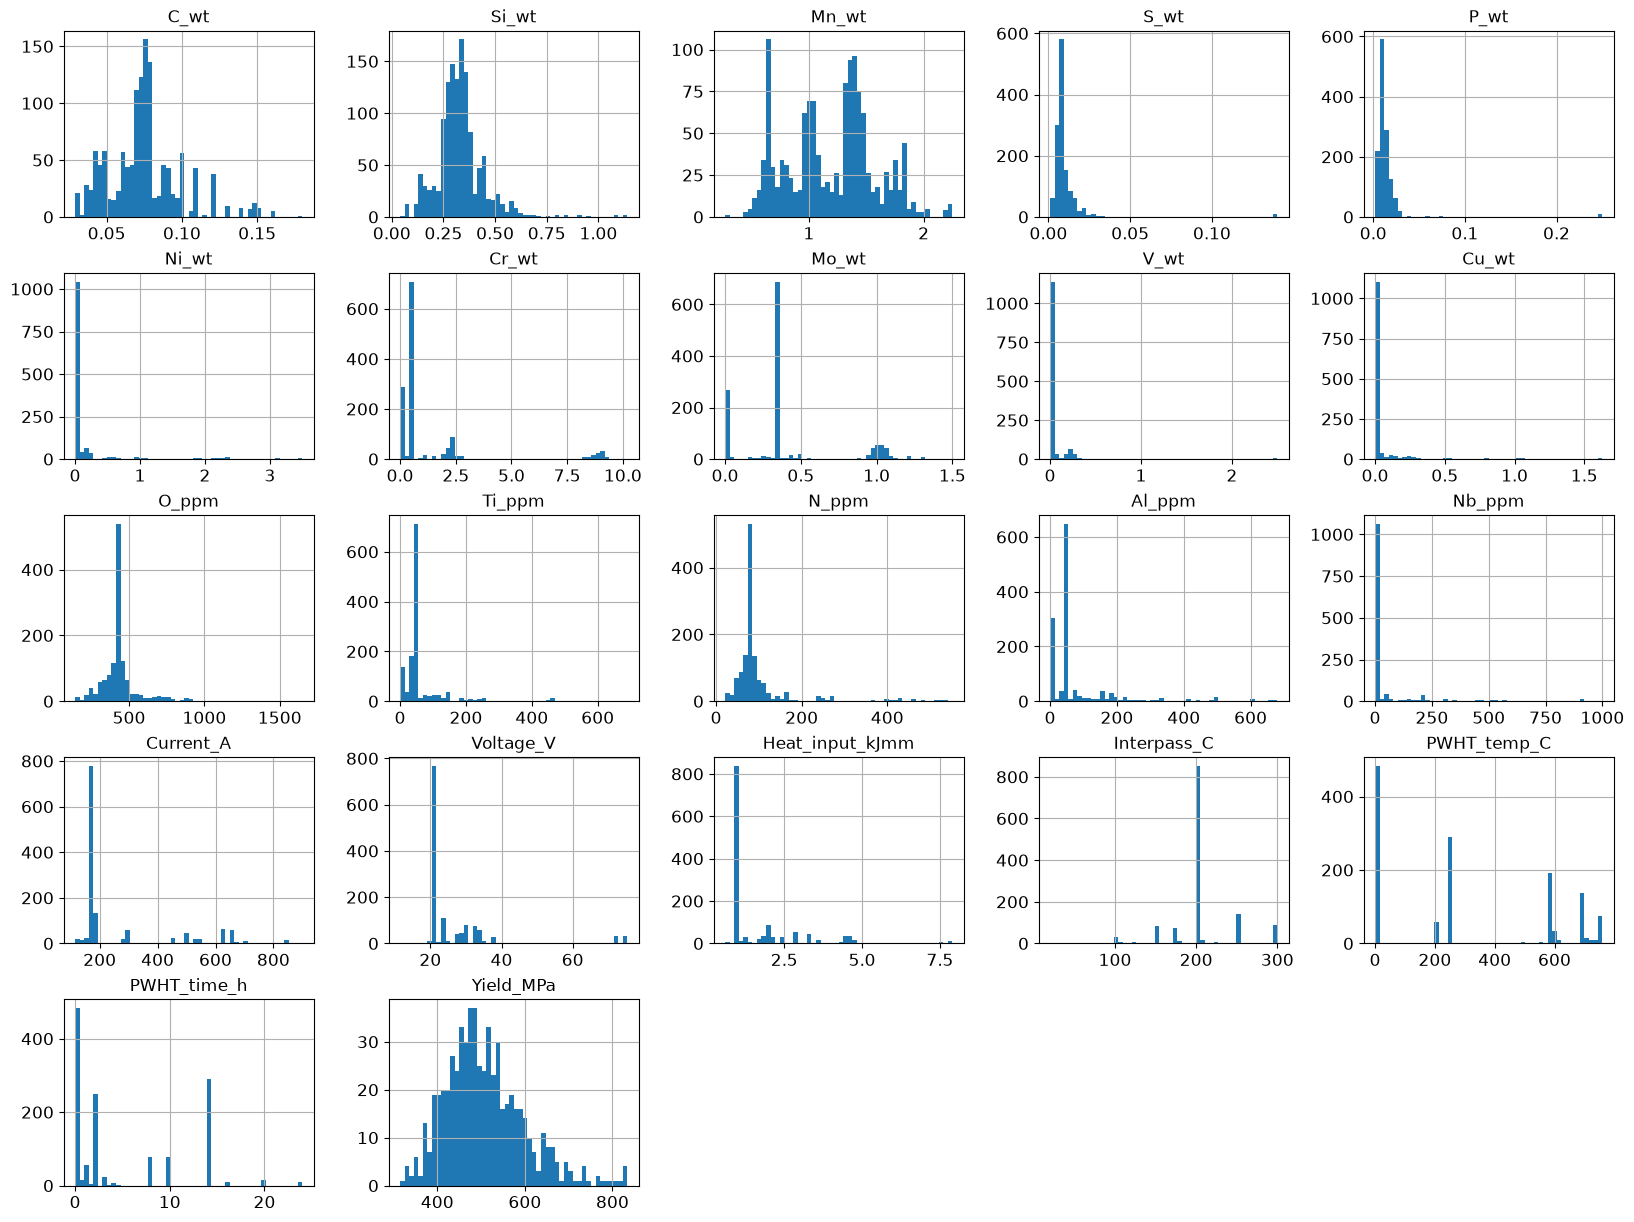

In [15]:
train.hist(bins=50, figsize=(20, 15))
plt.show()

### Scaling 
The distribution hsitogramms show that there features have very different scales. It is necessary to do some scaling.

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
train[num_cols] = scaler.fit_transform(train[num_cols])
test[num_cols] = scaler.transform(test[num_cols])

### One-hot encoding for categorical values

In [17]:
print("Categorical columns to encode:", cat_cols)

# Fit the one-hot column layout on train, then align test to it.
cat_cols_to_encode = [c for c in cat_cols if c in train.columns]
train = pd.get_dummies(
    train,
    columns=cat_cols_to_encode,
    drop_first=True,
    dtype=int,
)
test = pd.get_dummies(
    test,
    columns=[c for c in cat_cols_to_encode if c in test.columns],
    drop_first=True,
    dtype=int,
)

test = test.reindex(columns=train.columns, fill_value=0)

assert train.columns.equals(test.columns)
assert train.drop(columns=target).notna().all().all()
assert test.drop(columns=target).notna().all().all()

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Labeled rows in train:", train[target].notna().sum())
print("Unlabeled rows in train:", train[target].isna().sum())
train.filter(regex="AC_DC|Electrode_polarity|Weld_type").head()

Categorical columns to encode: Index(['AC_DC', 'Electrode_polarity', 'Weld_type'], dtype='str')
Train shape: (1321, 34)
Test shape: (331, 34)
Labeled rows in train: 613
Unlabeled rows in train: 708


,AC_DC_DC,Electrode_polarity_-,Electrode_polarity_0,Weld_type_GMAA,Weld_type_GTAA,Weld_type_MMA,Weld_type_NGGMA,Weld_type_NGSAW,Weld_type_SA,Weld_type_SAA,Weld_type_ShMA,Weld_type_TSA
306,1,0,0,0,0,1,0,0,0,0,0,0
192,1,0,0,0,0,1,0,0,0,0,0,0
309,1,0,0,0,0,1,0,0,0,0,0,0
1360,1,0,0,0,0,0,0,0,0,0,0,0
63,1,0,0,0,0,1,0,0,0,0,0,0


### ACP 

In [18]:
from sklearn.decomposition import PCA

# Copies indépendantes, sans modifier train et test
X_train_pca = train.drop(columns=[target]).copy()
X_test_pca = test.drop(columns=[target]).copy()

pca = PCA()
X_train_components = pca.fit_transform(X_train_pca)
X_test_components = pca.transform(X_test_pca)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("Nombre de variables initiales :", X_train_pca.shape[1])
print("Nombre de composantes :", pca.n_components_)
print(
    "Variance expliquée par les 2 premières composantes :",
    round(cumulative_variance[1] * 100, 2),
    "%"
)

Nombre de variables initiales : 33
Nombre de composantes : 33
Variance expliquée par les 2 premières composantes : 33.04 %


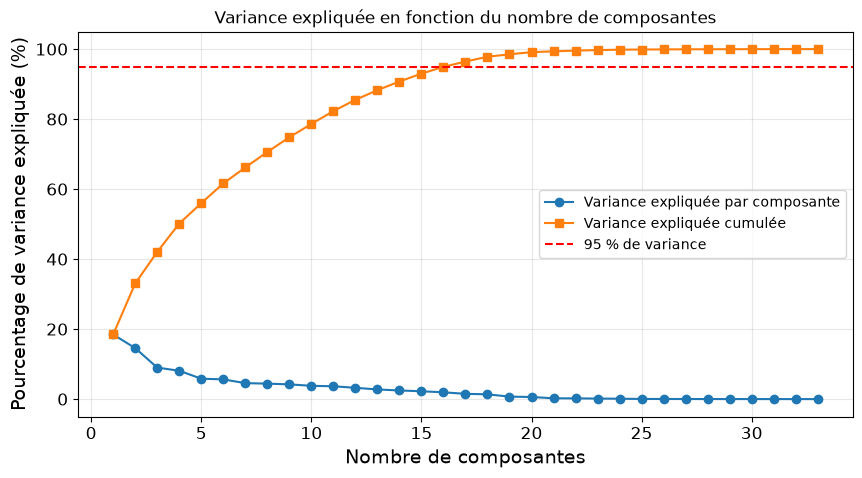

In [19]:
n_components = np.arange(1, len(explained_variance) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    n_components,
    explained_variance * 100,
    marker="o",
    label="Variance expliquée par composante"
)

plt.plot(
    n_components,
    cumulative_variance * 100,
    marker="s",
    label="Variance expliquée cumulée"
)

plt.xlabel("Nombre de composantes")
plt.ylabel("Pourcentage de variance expliquée (%)")
plt.title("Variance expliquée en fonction du nombre de composantes")
plt.axhline(95, color="red", linestyle="--", label="95 % de variance")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

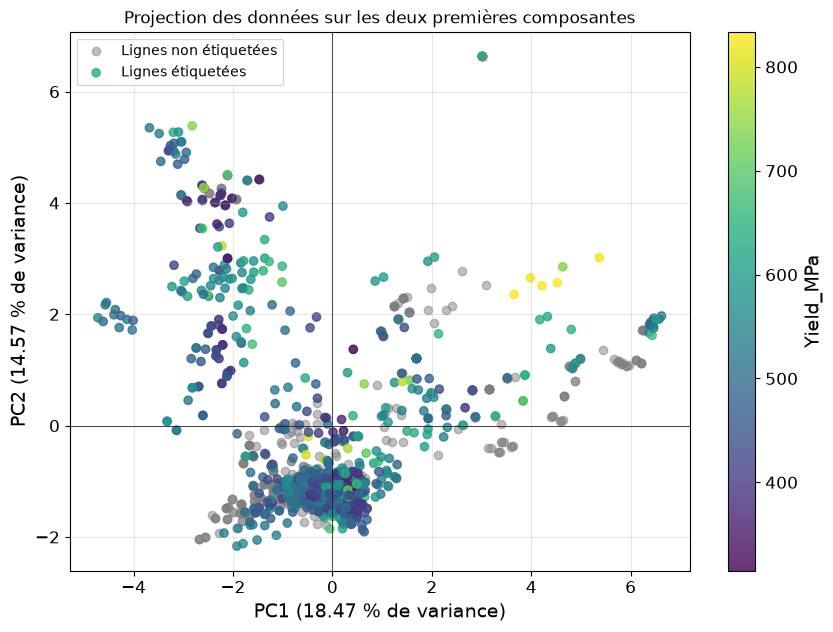

In [20]:
pc_train = pd.DataFrame(
    X_train_components[:, :2],
    columns=["PC1", "PC2"],
    index=train.index,
)

pc_train["Yield_MPa"] = train[target]

labeled_mask = pc_train["Yield_MPa"].notna()

plt.figure(figsize=(10, 7))

plt.scatter(
    pc_train.loc[~labeled_mask, "PC1"],
    pc_train.loc[~labeled_mask, "PC2"],
    color="gray",
    alpha=0.5,
    label="Lignes non étiquetées",
)

scatter = plt.scatter(
    pc_train.loc[labeled_mask, "PC1"],
    pc_train.loc[labeled_mask, "PC2"],
    c=pc_train.loc[labeled_mask, "Yield_MPa"],
    cmap="viridis",
    alpha=0.8,
    label="Lignes étiquetées",
)

plt.colorbar(scatter, label="Yield_MPa")
plt.xlabel(
    f"PC1 ({explained_variance[0] * 100:.2f} % de variance)"
)
plt.ylabel(
    f"PC2 ({explained_variance[1] * 100:.2f} % de variance)"
)
plt.title("Projection des données sur les deux premières composantes")
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 4. Model tuning, training, and performance evaluation

Hyperparameters are selected with cross-validation before the final models are trained. All supervised and semi-supervised evaluations use only test rows for which `Yield_MPa` is known.

In [21]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from xgboost import XGBRegressor

# Keep the test set untouched during hyperparameter selection.
train_labeled = train[target].notna()
test_labeled = test[target].notna()

X_train_labeled = train.loc[train_labeled].drop(columns=[target])
y_train_labeled = train.loc[train_labeled, target]
X_test_labeled = test.loc[test_labeled].drop(columns=[target])
y_test_labeled = test.loc[test_labeled, target]

cv = 3

ridge_search = GridSearchCV(
    Ridge(),
    {"alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
)
ridge_search.fit(X_train_labeled, y_train_labeled)

rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    {
        "n_estimators": [200, 400, 600],
        "max_depth": [None, 8, 16, 24],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": [0.6, 0.8, 1.0],
    },
    n_iter=12,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
)
rf_search.fit(X_train_labeled, y_train_labeled)

xgb_search = RandomizedSearchCV(
    XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
    ),
    {
        "n_estimators": [200, 400, 600],
        "max_depth": [2, 3, 4, 6],
        "learning_rate": [0.02, 0.05, 0.1],
        "subsample": [0.7, 0.85, 1.0],
        "colsample_bytree": [0.7, 0.85, 1.0],
        "min_child_weight": [1, 3, 5],
    },
    n_iter=12,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
)
xgb_search.fit(X_train_labeled, y_train_labeled)

best_estimators = {
    "Ridge": ridge_search.best_estimator_,
    "Random forest": rf_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_,
}

print("Best Ridge parameters:", ridge_search.best_params_)
print("Best random forest parameters:", rf_search.best_params_)
print("Best XGBoost parameters:", xgb_search.best_params_)

Best Ridge parameters: {'alpha': 100.0}
Best random forest parameters: {'n_estimators': 600, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.6, 'max_depth': 16}
Best XGBoost parameters: {'subsample': 0.85, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.85}


In [22]:
# Train each tuned estimator once on all labeled training rows.
models = {
    name: clone(estimator)
    for name, estimator in best_estimators.items()
}

supervised_results = []
for name, model in models.items():
    model.fit(X_train_labeled, y_train_labeled)
    prediction = model.predict(X_test_labeled)
    supervised_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_labeled, prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test_labeled, prediction)),
        "R2": r2_score(y_test_labeled, prediction),
    })

supervised_results_df = pd.DataFrame(supervised_results).sort_values("RMSE")
display(supervised_results_df.round(3))

,Model,MAE,RMSE,R2
2,XGBoost,20.563,34.277,0.882
1,Random forest,27.663,42.264,0.821
0,Ridge,53.977,73.450,0.458


In [23]:
# Semi-supervised pseudo-labeling for all three tuned model families.
unlabeled_mask = train[target].isna()
X_unlabeled = train.loc[unlabeled_mask].drop(columns=[target])

semi_supervised_results = []
semi_supervised_models = {}
pseudo_label_counts = {}

for name, estimator in best_estimators.items():
    # Bootstrap predictions provide a model-independent uncertainty estimate.
    bootstrap_predictions = []
    rng = np.random.default_rng(42)

    for _ in range(5):
        sample_indices = rng.integers(
            0,
            len(X_train_labeled),
            size=len(X_train_labeled),
        )
        bootstrap_model = clone(estimator)
        bootstrap_model.fit(
            X_train_labeled.iloc[sample_indices],
            y_train_labeled.iloc[sample_indices],
        )
        bootstrap_predictions.append(
            bootstrap_model.predict(X_unlabeled)
        )

    bootstrap_predictions = np.asarray(bootstrap_predictions)
    pseudo_y = bootstrap_predictions.mean(axis=0)
    pseudo_uncertainty = bootstrap_predictions.std(axis=0)
    uncertainty_threshold = np.quantile(pseudo_uncertainty, 0.25)
    confident = pseudo_uncertainty <= uncertainty_threshold

    X_pseudo = X_unlabeled.loc[confident]
    y_pseudo = pd.Series(pseudo_y[confident], index=X_pseudo.index)
    X_semi = pd.concat([X_train_labeled, X_pseudo])
    y_semi = pd.concat([y_train_labeled, y_pseudo])

    semi_model = clone(estimator)
    semi_model.fit(X_semi, y_semi)
    semi_prediction = semi_model.predict(X_test_labeled)

    semi_supervised_models[name] = semi_model
    pseudo_label_counts[name] = len(X_pseudo)
    semi_supervised_results.append({
        "Model": f"{name} + pseudo-labeling",
        "MAE": mean_absolute_error(y_test_labeled, semi_prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test_labeled, semi_prediction)),
        "R2": r2_score(y_test_labeled, semi_prediction),
    })

semi_supervised_results_df = pd.DataFrame(semi_supervised_results).sort_values("RMSE")
results_with_semi = pd.concat(
    [supervised_results_df, semi_supervised_results_df],
    ignore_index=True,
).sort_values("RMSE")

print("Unlabeled training rows:", len(X_unlabeled))
print("Confident pseudo-labels retained:", pseudo_label_counts)
display(results_with_semi.round(3))

Unlabeled training rows: 708
Confident pseudo-labels retained: {'Ridge': 177, 'Random forest': 178, 'XGBoost': 177}


,Model,MAE,RMSE,R2
3,XGBoost + pseudo-labeling,21.117,33.903,0.885
0,XGBoost,20.563,34.277,0.882
1,Random forest,27.663,42.264,0.821
4,Random forest + pseudo-labeling,27.802,42.354,0.820
5,Ridge + pseudo-labeling,53.998,73.448,0.458
2,Ridge,53.977,73.450,0.458


,importance
V_wt,0.174398
Mo_wt,0.090456
Voltage_V,0.077543
Ni_wt,0.071610
Nb_ppm,0.066810
Cr_wt,0.066024
Weld_type_TSA,0.057753
Mn_wt,0.048323
Current_A,0.041892
PWHT_temp_C,0.037982


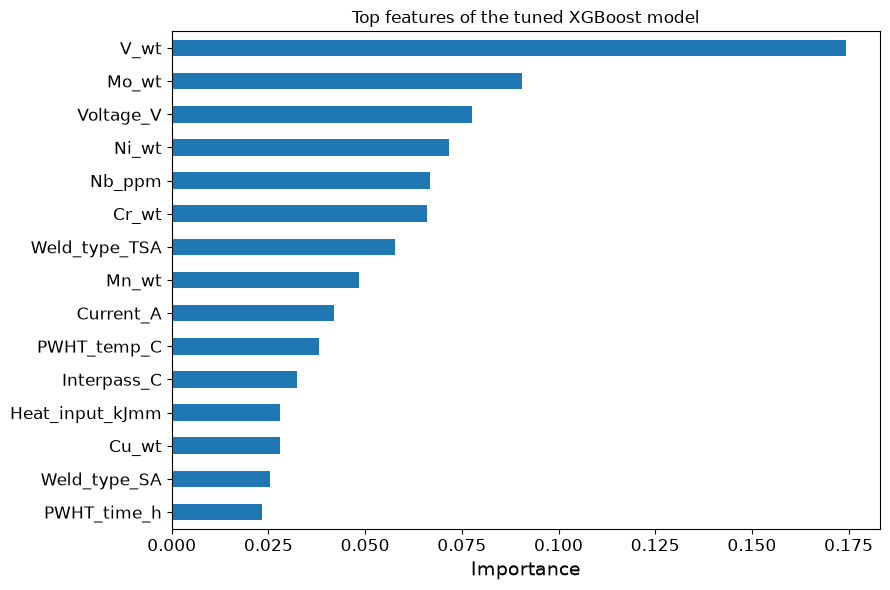

In [24]:
# Inspect the features used most by the best supervised model.
best_model = models["XGBoost"]
feature_importance = pd.Series(
    best_model.feature_importances_,
    index=X_train_labeled.columns,
).sort_values(ascending=False)

display(feature_importance.head(15).to_frame("importance"))

plt.figure(figsize=(9, 6))
feature_importance.head(15).sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top features of the tuned XGBoost model")
plt.tight_layout()
plt.show()

## 5. Comparative analysis and recommendations

### Comparative analysis of the models

The problem is a regression problem because `Yield_MPa` is a continuous target. The following metrics are therefore appropriate:

- **MAE** measures the average absolute prediction error in MPa. It is easy to interpret and less sensitive to extreme errors.
- **RMSE** is also expressed in MPa, but penalizes large errors more strongly. It is particularly relevant here because a large error in predicted yield strength may hide a potentially unsafe weld.
- **$R^2$** measures the proportion of target variability explained by the model. It is useful as a complementary metric, but it should not be used alone because it does not directly express the prediction error in MPa.

The results obtained on the labeled test rows are:

| Approach | MAE (MPa) | RMSE (MPa) | $R^2$ |
|---|---:|---:|---:|
| Tuned XGBoost | 20.563 | 34.277 | 0.882 |
| Tuned XGBoost + pseudo-labeling | 21.117 | 33.903 | 0.885 |
| Tuned Random Forest | 27.663 | 42.264 | 0.821 |
| Tuned Random Forest + pseudo-labeling | 27.877 | 42.215 | 0.821 |
| Tuned Ridge | 53.977 | 73.450 | 0.458 |
| Tuned Ridge + pseudo-labeling | 53.998 | 73.448 | 0.458 |

The tree-based methods clearly outperform Ridge. This indicates that the relation between the chemical composition, welding parameters, and `Yield_MPa` is nonlinear and involves interactions between variables. XGBoost is the most appropriate supervised model in this experiment. Pseudo-labeling produces a very small RMSE improvement for XGBoost, but its MAE becomes slightly worse. Therefore, the improvement is not uniform and should be confirmed with repeated cross-validation or several independent test splits before being considered robust.

### Recommended approach

For this dataset, the recommended approach is **tuned XGBoost**, with pseudo-labeling considered as an experimental extension rather than as the default model. The final choice should prioritize RMSE when large prediction errors are considered especially risky, while MAE should also be reported to describe the typical error.

The comparison remains subject to the limitation of a single train/test split. A stronger final study should repeat the split or use nested cross-validation, while keeping a final test set completely untouched.

### Recommendations for obtaining good weld quality

The feature-importance analysis identifies the following variables as the main predictive signals: `V_wt`, `Mo_wt`, `Voltage_V`, `Ni_wt`, `Nb_ppm`, `Cr_wt`, `Mn_wt`, `Current_A`, `PWHT_temp_C`, `Interpass_C`, `Heat_input_kJmm`, and `PWHT_time_h`.

Based on these results, the practical recommendations are:

1. **Control the chemical composition carefully**, especially vanadium, molybdenum, nickel, niobium, chromium, and manganese. These elements should be monitored against the specification of the material and the required mechanical properties.
2. **Control the electrical welding parameters**, particularly voltage and current, because they influence the heat delivered to the weld and therefore the resulting microstructure.
3. **Keep heat input and interpass temperature within a validated process window.** Large deviations may change cooling conditions and produce inconsistent mechanical properties.
4. **Define the post-weld heat-treatment temperature and duration from qualified procedures**, since both variables appear among the important predictors.
5. **Treat weld type as a process decision**, not merely as a categorical label. Different welding processes may require different current, voltage, heat-input, and thermal-treatment settings.
6. **Use XGBoost as a decision-support tool, not as a replacement for qualification tests.** Feature importance shows predictive association, not causality. Recommended parameter settings must therefore be confirmed by physical testing, standards, and engineering constraints.
7. **Measure and record the important variables consistently.** Better measurements of composition, voltage, current, temperature, and heat input will improve both model reliability and process control.

These recommendations describe the variables that should be controlled most carefully. They do not justify increasing or decreasing a variable automatically: the direction of its effect must be studied with partial-dependence or SHAP analysis and validated experimentally.